# Coin Value Identifier

This notebook follows the image breakdown workflow from `activity02.ipynb`, but applies it to coin recognition. Each stage makes one processing decision visible: image loading, channel inspection, segmentation, mask cleanup, connected-component labeling, feature measurement, denomination classification, and total-value calculation.

The example uses four calibrated coin sizes. Set `IMAGE_PATH` to a photograph of coins when applying the workflow to a real image.

## 1. Import the image-processing tools

NumPy stores image data as arrays, Matplotlib displays each intermediate image, OpenCV performs filtering and contour operations, and scikit-image measures connected regions.

In [7]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.measure import label, regionprops

## 2. Load the coin image

OpenCV reads color images in BGR order, so the image is converted to RGB before display. If no photograph is available, a controlled synthetic image is generated so every later cell can still be tested.

Source: Assets\coins.jpg
Image width: 2131px
Image height: 2842px
Channels: 3


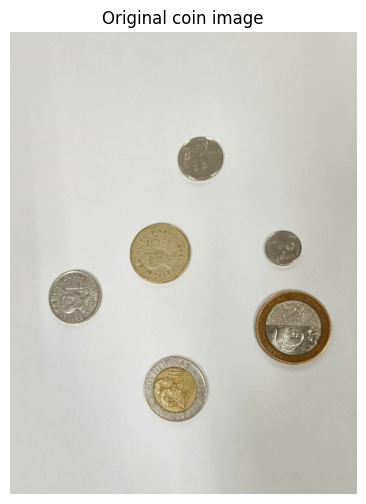

In [8]:
IMAGE_PATH = Path('Assets/coins.jpg')

def make_demo_image():
    canvas = np.zeros((480, 760, 3), dtype=np.uint8)
    canvas[:] = (35, 35, 35)
    coins = [(120, 150, 35), (300, 160, 45), (500, 150, 55),
             (180, 350, 35), (390, 340, 65), (610, 340, 45)]
    for center_x, center_y, radius in coins:
        cv2.circle(canvas, (center_x, center_y), radius, (185, 185, 185), -1)
        cv2.circle(canvas, (center_x, center_y), radius, (240, 240, 240), 3)
    return canvas

if IMAGE_PATH.exists():
    image_bgr = cv2.imread(str(IMAGE_PATH))
    if image_bgr is None:
        raise ValueError(f'OpenCV could not decode {IMAGE_PATH}')
    source_label = str(IMAGE_PATH)
else:
    image_bgr = make_demo_image()
    source_label = 'synthetic demo image'

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image_rgb.shape[:2]
print(f'Source: {source_label}')
print(f'Image width: {width}px')
print(f'Image height: {height}px')
print(f'Channels: {image_rgb.shape[2]}')

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title('Original coin image')
plt.axis('off')
plt.show()

## 3. Break the image into grayscale and color channels

Coin boundaries are easier to detect after reducing the three color channels to grayscale. The RGB channels are shown separately so lighting, shadows, or background colors can be diagnosed before thresholding.

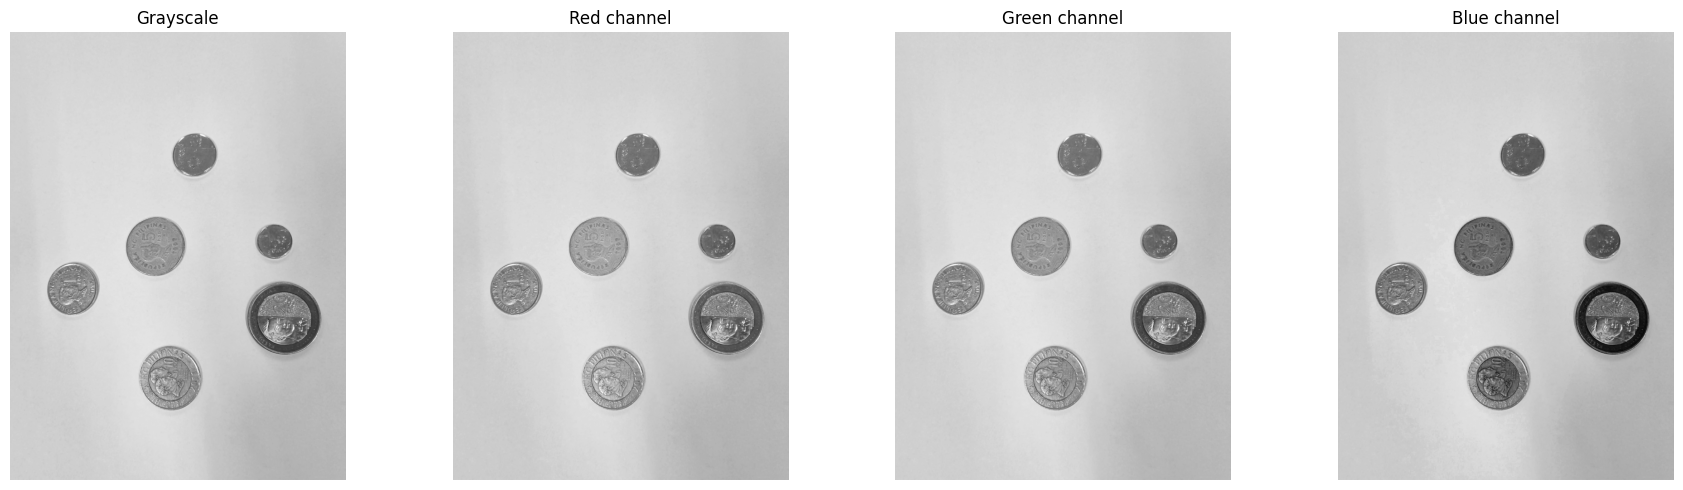

In [9]:
gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
red, green, blue = cv2.split(image_rgb)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for axis, channel, title in zip(axes, [gray, red, green, blue],
                           ['Grayscale', 'Red channel', 'Green channel', 'Blue channel']):
    axis.imshow(channel, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 4. Create a binary foreground mask

A binary mask stores foreground pixels as white and background pixels as black. Otsu's threshold chooses a gray-level split from the image histogram, which is more adaptable than hard-coding one brightness value.

Otsu threshold: 166.0


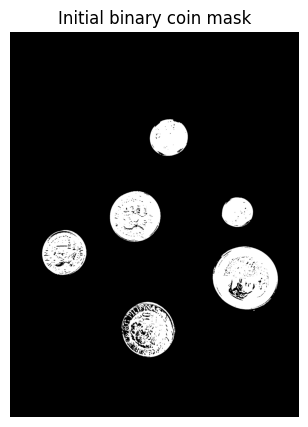

In [10]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
threshold_value, binary = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# If the background is brighter than the coins, invert the mask.
border_pixels = np.concatenate([binary[0, :], binary[-1, :], binary[:, 0], binary[:, -1]])
if border_pixels.mean() > 127:
    binary = cv2.bitwise_not(binary)

print(f'Otsu threshold: {threshold_value:.1f}')
plt.figure(figsize=(9, 5))
plt.imshow(binary, cmap='gray')
plt.title('Initial binary coin mask')
plt.axis('off')
plt.show()

## 5. Clean the mask with morphology

Opening removes isolated specks and closing repairs small gaps along coin edges. The result is a cleaner mask for connected-component analysis.

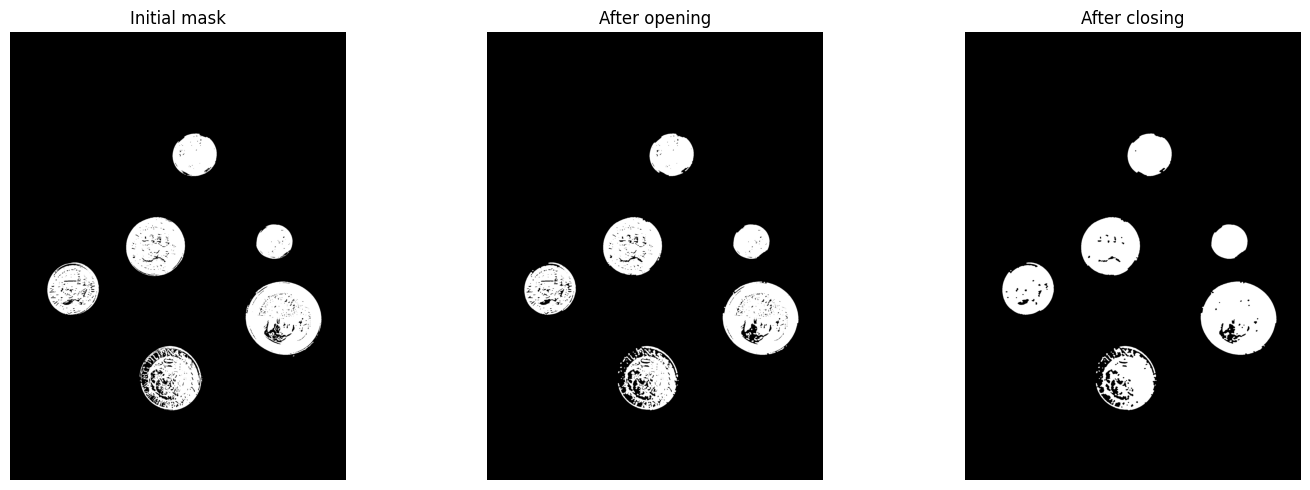

In [11]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
clean_mask = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, mask, title in zip(axes, [binary, opened, clean_mask],
                           ['Initial mask', 'After opening', 'After closing']):
    axis.imshow(mask, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 6. Label connected coin regions

Each connected white region is treated as one candidate coin. Very small regions are discarded as noise using `MIN_AREA`; the remaining regions retain their area, centroid, bounding box, and perimeter for classification.

## 7. Measure each coin and identify its value

The classifier supports both centavos and pesos. Every denomination is stored internally as centavos, so `25 centavos` is represented as `25` and `1 peso` as `100`. This prevents centavo coins from being incorrectly counted as whole pesos.

In [16]:
MIN_AREA = 5000
label_image = label(clean_mask > 0, connectivity=2)
regions = [region for region in regionprops(label_image) if region.area >= MIN_AREA]

print(f'Connected coin regions retained: {len(regions)}')
print('Coin region areas:', [int(region.area) for region in regions])

Connected coin regions retained: 6
Coin region areas: [57706, 104802, 38459, 78833, 162705, 87242]


In [24]:
# Calibrated from the supplied Philippine-coin image.
# Store all denominations as centavos to keep centavos and pesos consistent.
CALIBRATED_DENOMINATIONS = [
    {'label': '1 centavo', 'area': 38459, 'centavos': 1},
    {'label': '25 centavos', 'area': 57706, 'centavos': 25},
    {'label': '1 peso', 'area': 87242, 'centavos': 100},
    {'label': '5 pesos', 'area': 78833, 'centavos': 500},
    {'label': '10 pesos', 'area': 104802, 'centavos': 1000},
    {'label': '20 pesos', 'area': 162705, 'centavos': 2000},
]

coin_measurements = []
for index, region in enumerate(regions, start=1):
    perimeter = max(region.perimeter, 1.0)
    circularity = 4 * np.pi * region.area / (perimeter ** 2)
    calibration = min(
        CALIBRATED_DENOMINATIONS,
        key=lambda item: abs(item['area'] - region.area),
    )
    denomination = calibration['label']
    coin_measurements.append({
        'id': index,
        'denomination': denomination,
        'centavos': calibration['centavos'],
        'area': region.area,
        'circularity': circularity,
        'centroid': region.centroid,
        'bbox': region.bbox,
    })
    print(f"Coin {index}: area={region.area:.0f} px, "
          f"circularity={circularity:.2f}, value={denomination}")

Coin 1: area=57706 px, circularity=0.67, value=25 centavos
Coin 2: area=104802 px, circularity=0.29, value=10 pesos
Coin 3: area=38459 px, circularity=0.86, value=1 centavo
Coin 4: area=78833 px, circularity=0.21, value=5 pesos
Coin 5: area=162705 px, circularity=0.18, value=20 pesos
Coin 6: area=87242 px, circularity=0.03, value=1 peso


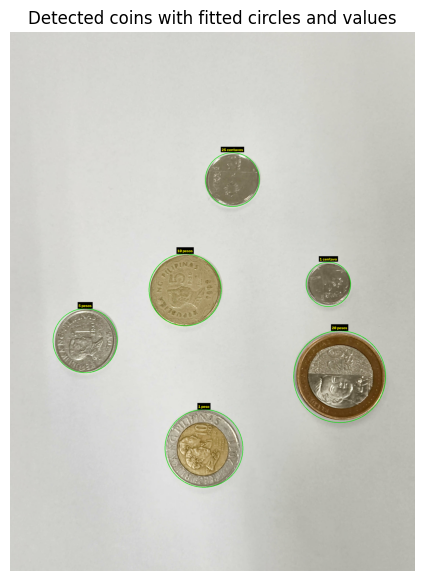

In [34]:
annotated = image_rgb.copy()
for coin, region in zip(coin_measurements, regions):
    region_points = np.column_stack((region.coords[:, 1], region.coords[:, 0])).astype(np.float32)
    (circle_x, circle_y), circle_radius = cv2.minEnclosingCircle(region_points)
    circle_center = (int(circle_x), int(circle_y))
    circle_radius = int(np.ceil(circle_radius))
    cv2.circle(annotated, circle_center, circle_radius, (0, 220, 0), 2)

    label_text = coin['denomination']
    (text_width, text_height), baseline = cv2.getTextSize(
        label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.65, 2
    )
    text_x = max(int(circle_x - text_width / 2), 2)
    text_y = max(int(circle_y - circle_radius - 8), text_height + baseline + 2)
    cv2.rectangle(
        annotated,
        (text_x - 4, text_y - text_height - baseline - 4),
        (text_x + text_width + 4, text_y + baseline + 4),
        (0, 0, 0),
        -1,
    )
    cv2.putText(
        annotated,
        label_text,
        (text_x, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 255, 0),
        2,
        cv2.LINE_AA,
    )

plt.figure(figsize=(11, 7))
plt.imshow(annotated)
plt.title('Detected coins with fitted circles and values')
plt.axis('off')
plt.show()

In [26]:
value_counts = {}
for coin in coin_measurements:
    denomination = coin['denomination']
    value_counts[denomination] = value_counts.get(denomination, 0) + 1

total_centavos = sum(coin['centavos'] for coin in coin_measurements)
total_pesos = total_centavos / 100

print('Coin count by denomination:')
for denomination, count in value_counts.items():
    print(f'  {denomination}: {count}')
print(f'Total detected coins: {len(coin_measurements)}')
print(f'Total value: {total_centavos} centavos = {total_pesos:.2f} pesos')

Coin count by denomination:
  25 centavos: 1
  10 pesos: 1
  1 centavo: 1
  5 pesos: 1
  20 pesos: 1
  1 peso: 1
Total detected coins: 6
Total value: 3626 centavos = 36.26 pesos
